# Time Series Spectroscopy with `time_series_gradient_emission`

Written by [Evert Nasedkin](mailto:nasedkinevert@gmail.com?subject=[petitRADTRANS]%20Retrievals).

Please cite pRT's retrieval package [(Nasedkin et al. 2024)](https://ui.adsabs.harvard.edu/abs/2024JOSS....9.5875N/abstract) in addition to pRT [(Mollière et al. 2019)](https://ui.adsabs.harvard.edu/abs/2019A%26A...627A..67M/abstract) if you make use of the retrieval package for your work.

This notebook demonstrates how to compute and retrieve **time-variable emission spectra** using the `time_series_gradient_emission` runtime-native model function together with `RetrievalConfig.add_time_series_data`.

The model uses the gradient (dT/d log P) temperature profile and computes `N_time` spectra at regularly spaced model timesteps spanning the observation window. Spectra at the actual observation times are obtained by linear interpolation along the time axis.

Two parameterisations are supported for time-variable parameters (and can coexist):

- **Per-timestep**: supply `{P}_t_0`, `{P}_t_1`, … so that timestep *i* uses the value of `{P}_t_i`.
- **Sinusoidal**: supply `{P}_amplitude`, `{P}_period`, `{P}_phase`, `{P}_offset` so that $P(t) = \text{offset} + A\sin(2\pi t / T + \phi)$.

This is useful for modelling, e.g., the rotationally modulated thermal emission of a hot Jupiter or the spectral variability of a directly imaged companion.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import petitRADTRANS as prt
from petitRADTRANS import physical_constants as cst
from petitRADTRANS.plotlib.style import set_petitradtrans_plot_style
from petitRADTRANS.retrieval.runtime import ModelContext, PhysicalParams
from petitRADTRANS.retrieval.models import time_series_gradient_emission

set_petitradtrans_plot_style()

print(f"JAX devices: {jax.devices()}")

Using pRT Plotting style!
JAX devices: [CpuDevice(id=0)]


## Setting up the `Radtrans` object

We use a small set of line species at low resolution to keep computation fast. The pressure grid (100 levels, $10^{-6}$–$10^{2}$ bar) is the same as in the other emission tutorials.

In [ ]:
line_species = (
    'H2O__POKAZATEL.R300',
    'CO-NatAbund.R300',
    'CH4.R300',
    'CO2.R300',
)

rayleigh_species = ('H2', 'He')
continuum_opacities = ('H2--H2', 'H2--He')
pressures = jnp.logspace(-6, 2, 100)

atmosphere = prt.radtrans.Radtrans(
    pressures=pressures,
    line_species=line_species,
    rayleigh_species=rayleigh_species,
    gas_continuum_contributors=continuum_opacities,
    cloud_species=(),
    wavelength_boundaries=(1.0, 5.0),
)

Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R300_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__YT34to10.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R300' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R300_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opa

## Sinusoidal time-variation: simulating a rotating brown dwarf

We model a brown dwarf with a time-varying pressure-temperature profile. The bottom-of-atmosphere temperature `T_bottom` varies sinusoidally with the object's rotation period ($P_\text{rot} = 10\,\text{h}$). All other parameters (PTslopes, chemistry) are treated as constant.

The observation window spans one full rotation period, sampled at 20 irregularly spaced epochs.

### Building `ModelContext` with observation times

`time_series_gradient_emission` reads the observation times from `model_context.model_metadata["observation_times"]` — simply pass the time array when constructing `ModelContext`.

In [3]:
# ---------- Observation setup ----------
rotation_period_s = 10.0 * 3600.0  # 10 hours in seconds

# 20 irregularly spaced observation epochs spanning one rotation period
rng = np.random.default_rng(42)
observation_times = np.sort(rng.uniform(0.0, rotation_period_s, 20))

print(f"Observation window: {observation_times[0]/3600:.2f} – {observation_times[-1]/3600:.2f} h")
print(f"Number of epochs:   {len(observation_times)}")

# ---------- ModelContext ----------
# N_time=15 model spectra are computed at regular intervals; the actual
# observation epochs are then obtained by linear interpolation.
n_model_timesteps = 15

ts_context = ModelContext(
    name='brown_dwarf_rotation',
    mode='evaluate',
    radtrans=atmosphere,
    adaptive_mesh_refinement=False,
    model_metadata={
        "observation_times": jnp.asarray(observation_times),
    },
)

Observation window: 0.64 – 9.76 h
Number of epochs:   20


### Building `PhysicalParams` with sinusoidal `T_bottom`

To make `T_bottom` vary sinusoidally, replace the scalar key `T_bottom` with the four keys `T_bottom_amplitude`, `T_bottom_period`, `T_bottom_phase`, and `T_bottom_offset`. The helper `_build_timestep_params` inside `time_series_gradient_emission` automatically resolves these into the correct scalar at each model timestep.

`N_time` must be set in `PhysicalParams` and should match the value passed to `ModelContext.model_metadata` (or `add_time_series_data`).

In [11]:
n_layers = 5

ts_params_sinusoidal = PhysicalParams.from_mapping({
    # System geometry
    'distance_to_system': 10.0 * cst.pc,
    'mass':               5.0 * cst.m_jup,
    'planet_radius':      1.2 * cst.r_jup_mean,

    # Gradient pressure-temperature profile
    'N_layers':                      n_layers,
    'top_of_atmosphere_pressure':    -3,
    'bottom_of_atmosphere_pressure':  2,

    # --- Sinusoidal T_bottom ---
    # T_bottom(t) = offset + amplitude * sin(2π t / period + phase)
    #             = 1500 + 300 * sin(2π t / (10 h))
    'T_bottom_amplitude': 25.0,              # K
    'T_bottom_period':    rotation_period_s,  # seconds
    'T_bottom_phase':     0.0,                # radians
    'T_bottom_offset':    1500.0,             # K  (mean bottom temperature)

    # PT gradients: deep layers have steeper gradients than upper layers
    'PTslope_1': 0.25,
    'PTslope_2': 0.20,
    'PTslope_3': 0.15,
    'PTslope_4': 0.10,
    'PTslope_5': 0.05,

    # Equilibrium chemistry
    'Fe/H':          0.5,
    'C/O':           0.55,
    'log_pquench':   2.0,

    # Number of model timesteps
    'N_time': n_model_timesteps,
})

### Computing the time series

Call `time_series_gradient_emission` exactly like any other runtime-native model. The returned `ModelResult.spectrum` has shape `(N_obs, N_wavelength)`, with one row per observation epoch.

In [12]:
ts_result = time_series_gradient_emission(
    ts_context,
    ts_params_sinusoidal,
    pt_plot_mode=False,
)

wavelengths   = ts_result.wavelengths           # (N_wavelength,)
spectra_2d    = ts_result.spectrum              # (N_obs, N_wavelength)
model_times   = ts_result.auxiliary_outputs["model_times"]
model_spectra = ts_result.auxiliary_outputs["model_spectra"]  # (N_time, N_wavelength)

print(f"Wavelength grid:  {wavelengths.shape}  ({wavelengths[0]:.2f} – {wavelengths[-1]:.2f} µm)")
print(f"Observed spectra: {spectra_2d.shape}   (N_obs × N_wavelength)")
print(f"Model spectra:    {model_spectra.shape}  (N_time × N_wavelength)")

Wavelength grid:  (482,)  (1.00 – 4.98 µm)
Observed spectra: (20, 482)   (N_obs × N_wavelength)
Model spectra:    (15, 482)  (N_time × N_wavelength)


### Visualising the time series: mean-divided spectrum

Dividing each observed spectrum by the time-averaged spectrum removes the broad spectral shape and highlights the time-variable component. The resulting 2D image has wavelength on the x-axis, time on the y-axis, and mean-divided flux as the colour axis.

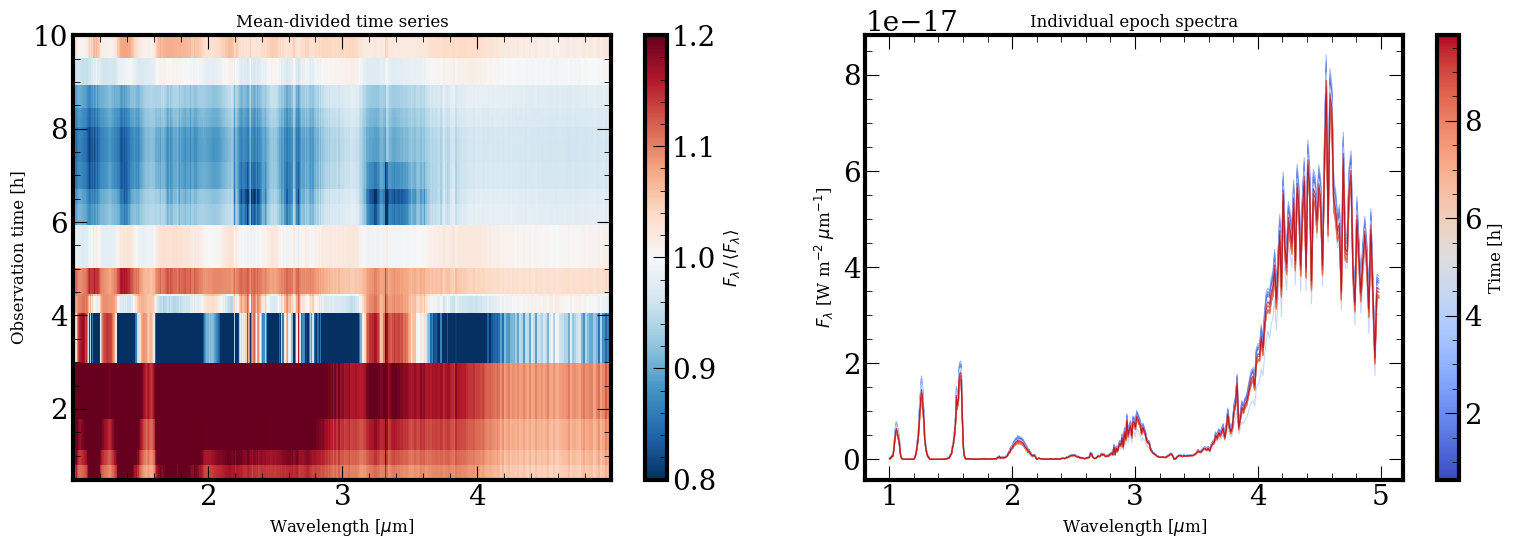

In [22]:
# Compute the time-mean spectrum and divide
mean_spectrum = jnp.mean(spectra_2d, axis=0)          # (N_wavelength,)
mean_divided  = spectra_2d / mean_spectrum[None, :]    # (N_obs, N_wavelength)

# Convert observation times to hours for the y-axis label
obs_hours = observation_times / 3600.0

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- 2-D colour map: wavelength vs time ---
ax = axes[0]
img = ax.pcolormesh(
    np.array(wavelengths),
    obs_hours,
    np.array(mean_divided),
    cmap='RdBu_r',
    vmin=0.8,
    vmax=1.2,
    shading='auto',
)
cbar = fig.colorbar(img, ax=ax)
cbar.set_label(r'$F_\lambda\,/\,\langle F_\lambda \rangle$', fontsize=12)
ax.set_xlabel(r'Wavelength [$\mu$m]', fontsize=12)
ax.set_ylabel('Observation time [h]', fontsize=12)
ax.set_title('Mean-divided time series', fontsize=12)

# --- Single-epoch spectra coloured by time ---
ax2 = axes[1]
cmap = plt.cm.coolwarm
norm = plt.Normalize(obs_hours.min(), obs_hours.max())
for i in range(len(observation_times)):
    ax2.plot(
        np.array(wavelengths),
        np.array(spectra_2d[i]),
        color=cmap(norm(obs_hours[i])),
        linewidth=0.8,
        alpha=0.7,
    )
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar2 = fig.colorbar(sm, ax=ax2)
cbar2.set_label('Time [h]', fontsize=12)
ax2.set_xlabel(r'Wavelength [$\mu$m]', fontsize=12)
ax2.set_ylabel(r'$F_\lambda$ [W m$^{-2}$ $\mu$m$^{-1}$]', fontsize=12)
ax2.set_title('Individual epoch spectra', fontsize=12)

fig.tight_layout()

### Inspecting the temperature-pressure profiles over time

Setting `pt_plot_mode=True` computes only the temperature profiles — one per model timestep. The returned `ModelResult.temperatures` has shape `(N_time, N_pressure)` and `auxiliary_outputs["model_times"]` gives the corresponding time grid.

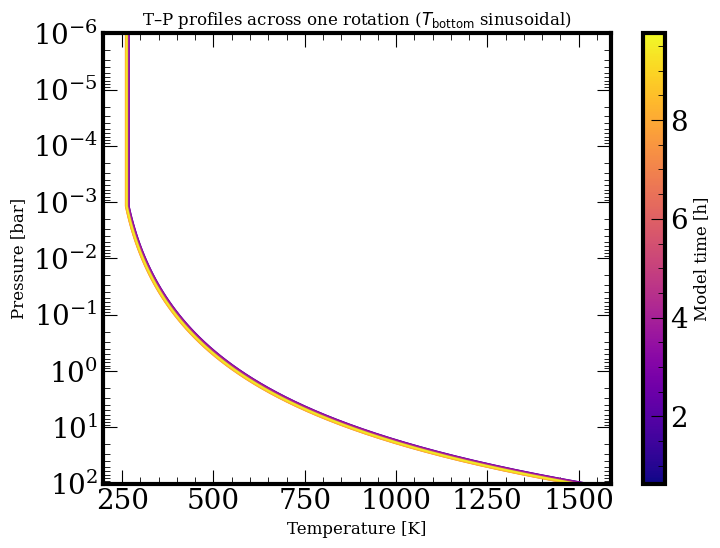

In [14]:
pt_result = time_series_gradient_emission(
    ts_context,
    ts_params_sinusoidal,
    pt_plot_mode=True,
)

# pt_result.temperatures has shape (N_time, N_pressure)
# pt_result.pressures has shape (N_pressure,)
all_temperatures = pt_result.temperatures  # (N_time, N_pressure)
pressure_grid    = pt_result.pressures     # (N_pressure,)
model_times_h    = np.array(pt_result.auxiliary_outputs["model_times"]) / 3600.0

fig, ax = plt.subplots(figsize=(8, 6))

cmap_pt = plt.cm.plasma
norm_pt = plt.Normalize(model_times_h.min(), model_times_h.max())
for i in range(len(model_times_h)):
    ax.plot(
        np.array(all_temperatures[i]),
        np.array(pressure_grid),
        color=cmap_pt(norm_pt(model_times_h[i])),
        linewidth=1.2,
        alpha=0.8,
    )
sm_pt = plt.cm.ScalarMappable(cmap=cmap_pt, norm=norm_pt)
sm_pt.set_array([])
cbar_pt = fig.colorbar(sm_pt, ax=ax)
cbar_pt.set_label('Model time [h]', fontsize=12)
ax.set_xlabel('Temperature [K]', fontsize=12)
ax.set_ylabel('Pressure [bar]', fontsize=12)
ax.set_ylim(1e2, 1e-6)
ax.set_yscale('log')
ax.set_title(r'T–P profiles across one rotation ($T_\mathrm{bottom}$ sinusoidal)', fontsize=12)
fig.tight_layout()

## Per-timestep parameterisation

For non-sinusoidal or empirically sampled variability you can supply one explicit value per model timestep. Append `_t_{i}` to any parameter name; at model timestep *i* the value of `{P}_t_i` is used.

Below we assign independent `T_bottom` values at each of the `N_time=5` model timesteps, representing a custom temperature sequence.

In [24]:
n_model_timesteps_tv = 5  # fewer timesteps for illustration

# 5 observation epochs (one per model timestep for simplicity)
obs_times_tv = np.linspace(0.0, rotation_period_s, n_model_timesteps_tv)

ts_context_tv = ModelContext(
    name='brown_dwarf_tv',
    mode='evaluate',
    radtrans=atmosphere,
    adaptive_mesh_refinement=False,
    model_metadata={
        "observation_times": jnp.asarray(obs_times_tv),
    },
)

# Explicit T_bottom values at each model timestep (e.g. following a light-curve shape)
t_bottom_values = [1200.0, 1250.0, 1300.0, 1240.0, 1190.0]  # K

tv_param_dict = {
    'distance_to_system': 10.0 * cst.pc,
    'mass':               5.0 * cst.m_jup,
    'planet_radius':      1.2 * cst.r_jup_mean,
    'N_layers':                      n_layers,
    'top_of_atmosphere_pressure':    -3,
    'bottom_of_atmosphere_pressure':  2,
    'PTslope_1': 0.25,
    'PTslope_2': 0.20,
    'PTslope_3': 0.15,
    'PTslope_4': 0.10,
    'PTslope_5': 0.05,
    'Fe/H':          0.5,
    'C/O':           0.55,
    'log_pquench':   2.0,
    'N_time': n_model_timesteps_tv,
}

# Add per-timestep T_bottom values
for i, t_val in enumerate(t_bottom_values):
    tv_param_dict[f'T_bottom_t_{i}'] = t_val

ts_params_tv = PhysicalParams.from_mapping(tv_param_dict)

ts_result_tv = time_series_gradient_emission(
    ts_context_tv,
    ts_params_tv,
    pt_plot_mode=False,
)

print(f"Spectra shape: {ts_result_tv.spectrum.shape}  (N_obs × N_wavelength)")


Spectra shape: (5, 482)  (N_obs × N_wavelength)


<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
/var/folders/66/46srd8053z5_wmg1tlyv021c0000gn/T/ipykernel_37625/4062237493.py:19: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('Per-timestep $T_\mathrm{bottom}$ — mean-divided time series', fontsize=12)


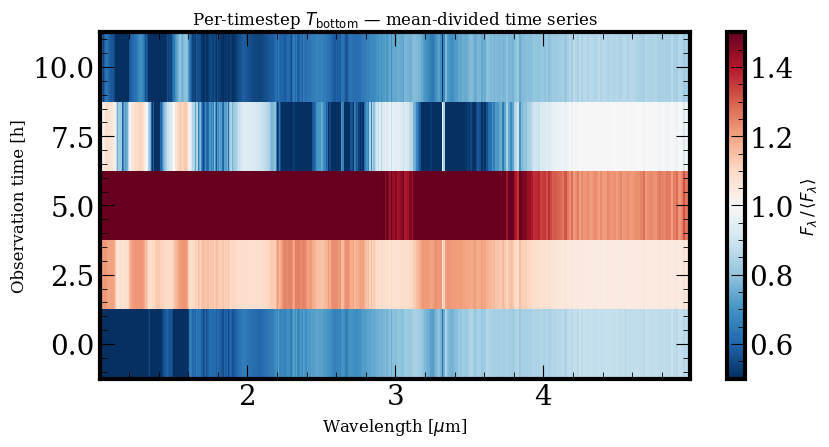

In [25]:
# Plot
mean_spectrum_tv = jnp.mean(ts_result_tv.spectrum, axis=0)
mean_divided_tv  = ts_result_tv.spectrum / mean_spectrum_tv[None, :]

fig, ax = plt.subplots(figsize=(9, 5))
img = ax.pcolormesh(
    np.array(ts_result_tv.wavelengths),
    obs_times_tv / 3600.0,
    np.array(mean_divided_tv),
    cmap='RdBu_r',
    vmin=0.5,
    vmax=1.5,
    shading='auto',
)
cbar = fig.colorbar(img, ax=ax)
cbar.set_label(r'$F_\lambda\,/\,\langle F_\lambda \rangle$', fontsize=12)
ax.set_xlabel(r'Wavelength [$\mu$m]', fontsize=12)
ax.set_ylabel('Observation time [h]', fontsize=12)
ax.set_title('Per-timestep $T_\mathrm{bottom}$ — mean-divided time series', fontsize=12)
fig.tight_layout()

## Setting up a time series retrieval

To retrieve parameters from time-resolved observations use `RetrievalConfig.add_time_series_data` instead of `add_data`. This method:

1. Creates a `TimeSeriesData` object that pairs the spectra with observation times.
2. Attaches the `time_series_config` dict (used by the runtime to pass `observation_times` into `model_context.model_metadata`).
3. Automatically registers the fixed `N_time` parameter.

The caller is then responsible for adding per-timestep or sinusoidal free parameters using the standard `add_parameter` calls.

### Simulating noisy observations

We first create mock observations by adding Gaussian noise to the previously computed model spectra.

In [16]:
rng_obs = np.random.default_rng(123)

# Relative noise level  (1% per spectral channel)
noise_fraction = 0.01

# Use the already-computed sinusoidal model spectra as the "truth"
true_spectra    = np.array(spectra_2d)  # (N_obs, N_wavelength)
noise_level     = noise_fraction * np.abs(true_spectra)
observed_spectra = true_spectra + rng_obs.standard_normal(true_spectra.shape) * noise_level

print(f"Observed spectra shape: {observed_spectra.shape}")
print(f"Median S/N per pixel:   {np.median(1.0 / noise_fraction):.0f}")

Observed spectra shape: (20, 482)
Median S/N per pixel:   100


### `RetrievalConfig` with `add_time_series_data`

We set up a retrieval that recovers the sinusoidal `T_bottom` parameters (`amplitude`, `period`, `phase`, `offset`) and the metallicity (`Fe/H`), keeping all other parameters fixed at their true values. We use JAXNS as the sampler because `time_series_gradient_emission` is a fully JAX-traceable runtime-native function.

In [17]:
import tensorflow_probability.substrates.jax as tfp

tfpd = tfp.distributions

from petitRADTRANS.retrieval import RetrievalConfig

retrieval_config = RetrievalConfig(
    retrieval_name='brown_dwarf_time_series',
    run_mode='retrieval',
    sampler_type='jaxns',           # fully differentiable; required for JAXNS
    pressures=np.array(pressures),
)

# -------------------------------------------------------------------
# 1.  Register the time series data set
#     add_time_series_data creates the TimeSeriesData object, attaches
#     the observation_times, and registers the fixed N_time parameter.
#
#     Passing radtrans_object=atmosphere reuses the Radtrans instance
#     we already created above, bypassing the internal Radtrans setup.
#     Alternatively, call add_line_species() on retrieval_config and
#     omit radtrans_object to let the config build the object itself.
#
#     Do NOT pass system_distance here: the physical parameter
#     'distance_to_system' in PhysicalParams already handles flux
#     scaling inside the runtime-native model.
# -------------------------------------------------------------------
retrieval_config.add_time_series_data(
    name='sinusoidal_rotation',
    observation_times=observation_times,
    model_generating_function=time_series_gradient_emission,
    n_model_timesteps=n_model_timesteps,
    sinusoidal_parameters=['T_bottom'],   # T_bottom_{amplitude,period,phase,offset}
    radtrans_object=atmosphere,           # reuse the Radtrans object built above
    # Inline data arrays (in practice load from files with filename_list)
    wavelengths=np.array(wavelengths),
    spectrum=observed_spectra,
    uncertainties=noise_level,
)

# -------------------------------------------------------------------
# 2.  Free parameters: sinusoidal T_bottom components
# -------------------------------------------------------------------
retrieval_config.add_parameter(
    'T_bottom_amplitude',
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=0.0, high=600.0),
    plot_in_corner=True,
    corner_label=r'$A_{T_\mathrm{bot}}$ [K]',
)
retrieval_config.add_parameter(
    'T_bottom_period',
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=3.0 * 3600.0, high=20.0 * 3600.0),
    plot_in_corner=True,
    corner_label=r'$P_{T_\mathrm{bot}}$ [s]',
)
retrieval_config.add_parameter(
    'T_bottom_phase',
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-np.pi, high=np.pi),
    plot_in_corner=True,
    corner_label=r'$\phi_{T_\mathrm{bot}}$ [rad]',
)
retrieval_config.add_parameter(
    'T_bottom_offset',
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=800.0, high=2500.0),
    plot_in_corner=True,
    corner_label=r'$T_\mathrm{bot,0}$ [K]',
)

# -------------------------------------------------------------------
# 3.  Free parameter: metallicity
# -------------------------------------------------------------------
retrieval_config.add_parameter(
    'Fe/H',
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-1.0, high=3.0),
    plot_in_corner=True,
    corner_label=r'[Fe/H]',
)

# -------------------------------------------------------------------
# 4.  Fixed parameters
# -------------------------------------------------------------------
fixed = {
    'distance_to_system':            10.0 * cst.pc,
    'mass':                          5.0 * cst.m_jup,
    'planet_radius':                 1.2 * cst.r_jup_mean,
    'N_layers':                      n_layers,
    'top_of_atmosphere_pressure':    -3,
    'bottom_of_atmosphere_pressure':  2,
    'PTslope_1': 0.25,
    'PTslope_2': 0.20,
    'PTslope_3': 0.15,
    'PTslope_4': 0.10,
    'PTslope_5': 0.05,
    'C/O':       0.55,
    'log_pquench': 2.0,
}
for pname, val in fixed.items():
    retrieval_config.add_parameter(pname, is_free_parameter=False, value=float(val))

print("Free parameters:")
for pname, param in retrieval_config.parameters.items():
    if param.is_free_parameter:
        print(f"  {pname}")
print(f"\nFixed N_time = {retrieval_config.parameters['N_time'].value}")

Free parameters:
  T_bottom_amplitude
  T_bottom_period
  T_bottom_phase
  T_bottom_offset
  Fe/H

Fixed N_time = 15


### Running the retrieval

With the `RetrievalConfig` fully built, pass it to `Retrieval` and call `.run()`. The runtime automatically detects the `MODEL_CONTRACT_RUNTIME_NATIVE` contract on `time_series_gradient_emission`, injects `observation_times` into the `ModelContext.model_metadata`, and evaluates the model completely within JAX so that JAXNS can use gradients.

```python
from petitRADTRANS.retrieval import Retrieval

retrieval = Retrieval(
    retrieval_config=retrieval_config,
    output_directory='output_bd_time_series/',
)

retrieval.run(n_live=200, max_samples=5000)
```

After the run completes, plotting functions are identical to those used in other retrieval tutorials:

```python
retrieval.plot_corner(output_directory='output_bd_time_series/')
retrieval.plot_spectra(output_directory='output_bd_time_series/')
```

## Summary

| Topic | Key point |
|-------|-----------|
| Model function | `time_series_gradient_emission` — gradient-profile emission, time-variable parameters auto-detected from naming conventions |
| Sinusoidal variation | Add `{P}_amplitude`, `{P}_period`, `{P}_phase`, `{P}_offset` to `PhysicalParams`; pass the base name to `sinusoidal_parameters` in `add_time_series_data` |
| Per-timestep variation | Add `{P}_t_0` … `{P}_t_{N-1}` to `PhysicalParams`; pass the base name to `time_varying_parameters` in `add_time_series_data` |
| Observation times | Passed via `ModelContext.model_metadata["observation_times"]` (set automatically by the retrieval runtime when using `add_time_series_data`) |
| `N_time` | Fixed parameter auto-registered by `add_time_series_data`; controls the number of model spectra computed before interpolation |
| Sampler | JAXNS is recommended: the model is fully JAX-traceable and supports automatic differentiation |
| Data class | `TimeSeriesData` wraps the 2-D `(N_obs, N_wavelength)` spectrum array together with the observation times |

For further reading see the [runtime-native models tutorial](./retrieval_runtime_models.ipynb) and the [JAXNS emission tutorial](./retrieval_jax_runtime_emission_tutorial.ipynb).